### 1. Setup and loading

In [1]:
import sys                    
sys.path.append("..")           

import numpy as np               
import pandas as pd              
import matplotlib.pyplot as plt  

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet   # regression models
from sklearn.ensemble import HistGradientBoostingRegressor                     # boosting (class "Bagged Trees and Random Forests")
from sklearn.model_selection import cross_val_score, PredefinedSplit, RandomizedSearchCV   # cross-validation with our saved folds
from sklearn.pipeline import Pipeline                                    # preprocessing + model in one object
from sklearn.metrics import mean_squared_error, mean_absolute_error      # error measures
from sklearn.metrics import roc_auc_score                                # ranking quality (class "Classification Metrics")

from src.utils import SEED, load_data, select_by_quota, recall_at_quota, within_village_auc   # shared group code
from src.features import SET_A, without_village_level, make_preprocessor                    # shared feature lists + preprocessing
from src.features import skewed, other_numeric, binary                                      # which column gets which treatment

print("SEED:", SEED)   # check that the shared seed is loaded (should be 40)

train, test = load_data()   # training villages (with their fold) and test villages, made in 01_data_prep


SEED: 40


### 2. Features (X), target (Y), train and test split

In [2]:
# Features: set A without the village-level columns
features = without_village_level(SET_A)   # 50 government-formula variables + 3 missing-value indicators
target = "LOGCONSUMPTION"                 # what we predict

print("number of features:", len(features))   # should be 53
print(features)

number of features: 53
['pcfloor', 'tfloor', 'twall', 'troof', 'toilet', 'water', 'lighting', 'fcook', 'house', 'hhsize', 'hhsize2', 'age04', 'eschild', 'jschild', 'sschild', 'depratio', 'hhage', 'hhage2', 'hhmale', 'hhmarried', 'hhmalemarr', 'hheduc2', 'hheduc3', 'hheduc4', 'hhsector1', 'hhsector2', 'hhsector3', 'formal', 'informal', 'higheduc2', 'higheduc3', 'higheduc4', 'credit', 'se2_17', 'se2_11_12', 'se2_125', 'se2_126_127', 'se2_119', 'se2_117', 'se2_115', 'se2_13_15', 'se2_14', 'se2_114', 'se2_18', 'se2_124', 'se2_122_123', 'se5_110', 'se5_11_12', 'se5_15_16', 'se2_138', 'hheduc_missing', 'no_workingage', 'pcfloor_missing']


We leave out the village-level columns because urban, district and village facilities are the same for every household in a village, so they cannot change the ranking within a village. 

In [3]:
# Train and test villages
print("train:", train.shape, "| villages:", train["hhea"].nunique())   # rows, columns, villages
print("test: ", test.shape, "| villages:", test["hhea"].nunique())
print("no village in both:", set(train["hhea"]).isdisjoint(test["hhea"]))   # must be True

train: (4090, 113) | villages: 512
test:  (1023, 112) | villages: 128
no village in both: True


We split by village because the model will be used in new villages. Households in one village share prices, roads and jobs. If neighbours were in both train and test, the test score would look too good. So we use the 128 test villages from 01_data_prep, and no village is in both parts.

In [4]:
# Features (X) and target (y) for training (the test villages are only used in 09_final_test, with the whole group)
X_train = train[features].astype(float)   # features as decimal numbers (<NA> becomes NaN, filled later in the pipeline)
y_train = train[target]                   # target for training

print("X_train:", X_train.shape, "| y_train:", y_train.shape)   # rows, columns
display(X_train.head())                   # first 5 training households

na = X_train.isna().sum()                 # missing values per column (train)
print(na[na > 0])                         # only columns with missing values

X_train: (4090, 53) | y_train: (4090,)


,pcfloor,tfloor,twall,troof,toilet,water,lighting,fcook,house,hhsize,...,se2_18,se2_124,se2_122_123,se5_110,se5_11_12,se5_15_16,se2_138,hheduc_missing,no_workingage,pcfloor_missing
0,24.75,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,4.0,...,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
1,10.00,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,8.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
2,22.50,1.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,4.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
3,28.50,1.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,2.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,60.00,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


pcfloor         42
toilet           7
water            1
depratio       177
hhage            4
hhage2           4
se2_122_123      4
se5_110          1
dtype: int64


### 3. Missing values: fill with the training median (inside the pipeline)

The regression models cannot work with missing values. So we will fill every gap with the median of the training data, and the 0/1 columns with their most frequent value.
We do not want to just delete these households because we would lose about 6% of the training data. Also, in real life the government must rank every household, even if one answer is missing.
We take the median instead of the mean because some features are very skewed and the median shows the typical household.

In [5]:
# Which columns get which treatment in make_preprocessor (src/features.py)
print("skewed numbers (median fill, then Yeo-Johnson):", skewed(features))
print("other numbers (median fill):                    ", other_numeric(features))
print("0/1 columns (most frequent value):              ", len(binary(features)), "columns")

skewed numbers (median fill, then Yeo-Johnson): ['pcfloor', 'eschild', 'depratio']
other numbers (median fill):                     ['hhsize', 'hhsize2', 'age04', 'jschild', 'sschild', 'hhage', 'hhage2']
0/1 columns (most frequent value):               43 columns


### 4. Scaling (inside the pipeline)

The features are measured in very different units: floor area in m2, age squared in thousands, assets as 0/1. Scaling puts them all on the same scale (mean 0, standard deviation 1). This is very important for Ridge and Lasso, as they punish large coefficients. A coefficient's size depends on the unit of its feature. Without scaling, a feature measured in small numbers would get a big coefficient and be punished more, only because of its unit. After scaling, the penalty is fair to every feature. For the OLS, scaling does not change the predictions. But it makes the coefficients comparable: each one shows the effect of one standard deviation more of that feature.

In [6]:
# Preprocessing 
prep = make_preprocessor(features)                                   # median fill + Yeo-Johnson + scaling
X_train_prep = pd.DataFrame(prep.fit_transform(X_train),             # learned on the training data only
                            columns=prep.get_feature_names_out())    # column names after preprocessing

cols = ["pcfloor", "hhsize", "hhage2", "toilet"]                     # a few example features
print("train before preprocessing:")
display(X_train[cols].agg(["mean", "std"]).round(2))                 # original units
print("train after preprocessing:")
display(X_train_prep[cols].agg(["mean", "std"]).round(2))            # mean 0, std 1
print("missing values left:", X_train_prep.isna().sum().sum())       # should be 0

train before preprocessing:


,pcfloor,hhsize,hhage2,toilet
mean,24.60,4.35,2499.37,0.65
std,29.19,1.94,1484.73,0.48


train after preprocessing:


,pcfloor,hhsize,hhage2,toilet
mean,-0.0,-0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0


missing values left: 0


**Result:**
- Before preprocessing, the features have very different sizes: `hhage2` has a mean of about 2,500, `pcfloor` about 25, `toilet` about 0.65.
- After preprocessing, every training feature has mean 0 and standard deviation 1, and no missing values are left.

### 5. OLS (linear regression without penalty)

In [7]:
# Cross-validation folds: the saved village folds from 01_data_prep
cv = PredefinedSplit(train["fold"])  

print("number of folds:", cv.get_n_splits())     # should be 5
for k, (train_idx, val_idx) in enumerate(cv.split()):  # check each round
    print(f"round {k}: train {len(train_idx)} | validation {len(val_idx)}")

number of folds: 5
round 0: train 3268 | validation 822
round 1: train 3268 | validation 822
round 2: train 3275 | validation 815
round 3: train 3275 | validation 815
round 4: train 3274 | validation 816


In [8]:
# Cross-validation error of OLS
ols = Pipeline([
    ("prep", make_preprocessor(features, drop_first=True)),   # fill + Yeo-Johnson + scale
    ("model", LinearRegression()),                            # OLS model, no penalty
])
cv_score = cross_val_score(ols, X_train, y_train, cv=cv,
                           scoring="neg_mean_squared_error")  # preprocessing is learned again in every round
ols_cv_mse = -np.mean(cv_score)                               # flip the sign, average over the 5 folds

print("MSE per fold:", (-cv_score).round(4))                   # error in each validation fold
print(f"OLS CV MSE:  {ols_cv_mse:.4f}")                       
print(f"OLS CV RMSE: {np.sqrt(ols_cv_mse):.4f}")               
print(f"MSE if I always guess the mean: {y_train.var():.4f}")  

MSE per fold: [0.2373 0.2106 0.2573 0.2453 0.2204]
OLS CV MSE:  0.2341
OLS CV RMSE: 0.4839
MSE if I always guess the mean: 0.4549


In [9]:
# Fit OLS on all training households and look at the coefficients
ols.fit(X_train, y_train)                                       # preprocessing + OLS, learned on all training data
names = ols.named_steps["prep"].get_feature_names_out()         # column names after preprocessing
ols_coefs = pd.Series(ols.named_steps["model"].coef_, index=names)   # coefficients with the right names

print(f"intercept: {ols.named_steps['model'].intercept_:.3f}")  # prediction for an average household
print(f"mean of y_train: {y_train.mean():.3f}")               
top = ols_coefs.abs().sort_values(ascending=False).index[:10]   # names of the 10 largest coefficients (by size)
display(ols_coefs.loc[top].round(3))                            

intercept: 6.062
mean of y_train: 6.062


hhsize        -0.571
hhsize2        0.346
pcfloor        0.079
se2_117        0.072
fcook          0.069
se2_125        0.067
se2_126_127    0.067
se2_119        0.061
hhage2        -0.058
se2_18         0.053
dtype: float64

### 6. Ridge and Lasso

Ridge and Lasso are OLS plus a penalty for large coefficients The alpha sets how strong the penalty is.
- Ridge punishes the squared coefficients. It makes all of them smaller, but none becomes exactly 0. This helps when features carry similar information (e.g. `hhage` and `hhage2`, or `hhmale` and `hhmalemarr`). OLS can then give them large opposite weights, and Ridge calms this down.
- Lasso punishes the absolute size of the coefficients. It can set some of them exactly to 0, so it also chooses features.
- alpha = 0 is plain OLS. A very large alpha pushes all coefficients to 0, and the model only predicts the mean.

In [10]:
# Penalty strengths to try (grids from our project outline, section 7)
alphas_ridge = np.logspace(-3, 3, 20)   # Ridge: 20 values from 0.001 to 1000, evenly spread on a log scale
alphas_lasso = np.logspace(-4, 0, 20)   # Lasso: 20 values from 0.0001 to 1

print(f"Ridge: {len(alphas_ridge)} values from {alphas_ridge.min()} to {alphas_ridge.max()}")
print(f"Lasso: {len(alphas_lasso)} values from {alphas_lasso.min()} to {alphas_lasso.max()}")

Ridge: 20 values from 0.001 to 1000.0
Lasso: 20 values from 0.0001 to 1.0


#### Ridge
For each alpha, we compute the CV error with the same 5 village folds. Then we pick the alpha with the lowest error.

In [11]:
# Ridge: CV error for every alpha
ridge_scores = []                                            # CV MSE for each alpha
for alpha in alphas_ridge:                                   # try each alpha
    ridge_model = Pipeline([
        ("prep", make_preprocessor(features)),              
        ("model", Ridge(alpha=alpha)),                       # Ridge with this penalty
    ])
    cv_score = cross_val_score(ridge_model, X_train, y_train, cv=cv,
                               scoring="neg_mean_squared_error")  
    ridge_scores.append(-np.mean(cv_score))                  # flip the sign, save the average MSE

best_alpha_ridge = alphas_ridge[np.argmin(ridge_scores)]     # alpha with the lowest CV error
best_score_ridge = np.min(ridge_scores)                      # that lowest CV error

print(f"Best alpha: {best_alpha_ridge:.3f}")
print(f"Ridge CV MSE: {best_score_ridge:.5f} | OLS CV MSE: {ols_cv_mse:.5f}")

Best alpha: 6.158
Ridge CV MSE: 0.23411 | OLS CV MSE: 0.23415


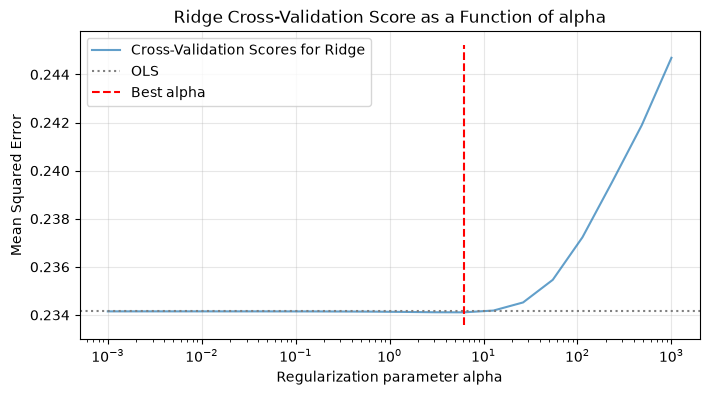

In [12]:
# Plot: Ridge CV error for each alpha
fig, ax = plt.subplots(figsize=(8, 4))

# CV error for each alpha that was tried
ax.plot(alphas_ridge, ridge_scores,alpha=0.7, label="Cross-Validation Scores for Ridge")
# OLS for comparison
ax.axhline(ols_cv_mse, color="grey", linestyle=":", label="OLS")
# The chosen alpha
ax.vlines(best_alpha_ridge, ax.get_ylim()[0], ax.get_ylim()[1], linestyle="--", color="red", label="Best alpha")

# Aesthetics
ax.set_xscale("log")  # alphas are spread on a log scale
ax.set_xlabel("Regularization parameter alpha")
ax.set_ylabel("Mean Squared Error")
ax.set_title("Ridge Cross-Validation Score as a Function of alpha")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

In [13]:
# Fit Ridge with the best alpha on all training households
ridge = Pipeline([
    ("prep", make_preprocessor(features)),                  
    ("model", Ridge(alpha=best_alpha_ridge)),     # Ridge with the chosen penalty
])
ridge.fit(X_train, y_train)                                 
ridge_coefs = pd.Series(ridge.named_steps["model"].coef_,
                        index=ridge.named_steps["prep"].get_feature_names_out())   

compare = pd.DataFrame({"OLS": ols_coefs, "Ridge": ridge_coefs})   # side by side (matched by name)
display(compare.loc[top].round(3))                                 # same 10 features as in the OLS table

,OLS,Ridge
hhsize,-0.571,-0.543
hhsize2,0.346,0.323
pcfloor,0.079,0.081
se2_117,0.072,0.072
fcook,0.069,0.069
se2_125,0.067,0.067
se2_126_127,0.067,0.067
se2_119,0.061,0.061
hhage2,-0.058,-0.046
se2_18,0.053,0.052


#### Lasso

In [14]:
# Lasso: CV error for every alpha
lasso_scores = []                                            # CV MSE for each alpha
for alpha in alphas_lasso:                                   # try each alpha
    lasso_model = Pipeline([
        ("prep", make_preprocessor(features)),              
        ("model", Lasso(alpha=alpha, max_iter=10000)),       # Lasso with this penalty 
    ])
    cv_score = cross_val_score(lasso_model, X_train, y_train, cv=cv,
                               scoring="neg_mean_squared_error")   # same village folds as OLS and Ridge
    lasso_scores.append(-np.mean(cv_score))                  # flip the sign, save the average MSE

best_alpha_lasso = alphas_lasso[np.argmin(lasso_scores)]     # alpha with the lowest CV error
best_score_lasso = np.min(lasso_scores)                      # that lowest CV error

print(f"Best alpha: {best_alpha_lasso:.4f}")
print(f"Lasso CV MSE: {best_score_lasso:.5f} | OLS CV MSE: {ols_cv_mse:.5f}")

Best alpha: 0.0007
Lasso CV MSE: 0.23406 | OLS CV MSE: 0.23415


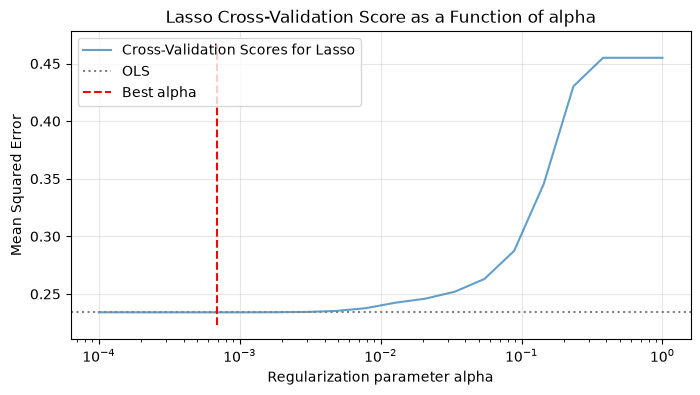

In [15]:
# Plot: Lasso CV error for each alpha
fig, ax = plt.subplots(figsize=(8, 4))

# CV error for each alpha that was tried
ax.plot(alphas_lasso, lasso_scores,
        alpha=0.7, label="Cross-Validation Scores for Lasso")
# OLS for comparison
ax.axhline(ols_cv_mse, color="grey", linestyle=":", label="OLS")
# The chosen alpha
ax.vlines(best_alpha_lasso, ax.get_ylim()[0], ax.get_ylim()[1], linestyle="--", color="red", label="Best alpha")

# Aesthetics
ax.set_xscale("log")        # alphas are spread on a log scale
ax.set_xlabel("Regularization parameter alpha")
ax.set_ylabel("Mean Squared Error")
ax.set_title("Lasso Cross-Validation Score as a Function of alpha")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

In [16]:
# Fit Lasso with the best alpha on all training households. Which features did it drop?
lasso = Pipeline([
    ("prep", make_preprocessor(features)),                      
    ("model", Lasso(alpha=best_alpha_lasso, max_iter=10000)),    # Lasso with the chosen penalty
])
lasso.fit(X_train, y_train)                                      
lasso_coefs = pd.Series(lasso.named_steps["model"].coef_,
                        index=lasso.named_steps["prep"].get_feature_names_out())   
zero = lasso_coefs[lasso_coefs == 0].index.tolist()              # features with coefficient exactly 0

print(f"coefficients set to 0: {len(zero)} of {len(features)}")
print(zero)                                                      # names of the dropped features
top_lasso = lasso_coefs.abs().sort_values(ascending=False).index[:10]   # 10 largest Lasso coefficients (by size)
display(lasso_coefs.loc[top_lasso].round(3))                            # show them with their sign

coefficients set to 0: 3 of 53
['eschild', 'hhage', 'hhsector1']


hhsize        -0.537
hhsize2        0.318
pcfloor        0.081
se2_117        0.072
fcook          0.069
se2_125        0.067
se2_126_127    0.066
se2_119        0.062
se2_18         0.052
se2_115        0.048
dtype: float64

#### Comparison of OLS, Ridge and Lasso (cross-validation)

In [17]:
# Compare the CV errors of the three models
cv_results = pd.DataFrame({
    "Model":  ["OLS", "Ridge", "Lasso"],                           # model names
    "alpha":  [0, best_alpha_ridge, best_alpha_lasso],             # chosen penalty (OLS = no penalty)
    "CV MSE": [ols_cv_mse, best_score_ridge, best_score_lasso],    # average CV error
}).set_index("Model").sort_values("CV MSE")                        # lowest error first
cv_results["CV RMSE"] = np.sqrt(cv_results["CV MSE"])              # error in log-consumption units

display(cv_results.round(5))                                       # 5 decimals, the differences are tiny

,alpha,CV MSE,CV RMSE
Model,,,
Lasso,0.00070,0.23406,0.48380
Ridge,6.15848,0.23411,0.48385
OLS,0.00000,0.23415,0.48389


**Result:**

All three models have almost the same CV error. Lasso has 0.23406 (alpha 0.0007), Ridge 0.23411 (alpha 6.16) and OLS 0.23415. In log consumption, this is an RMSE of about 0.484 for all three.

The differences between the models are much smaller than the differences between the folds. For OLS, the error goes from 0.211 to 0.257 depending on the fold. The models differ by less than 0.0001. So the differences between OLS, Ridge and Lasso are only noise, and none of them is really better. 

The best alphas are small, so Ridge and Lasso stay very close to OLS. Lasso sets only 3 of 53 coefficients to 0 (eschild, hhage, hhsector1). Their information is mostly also in other features, like hhsize, age04 and hhage2.

The penalty does not help because we have 4,090 training households and only 53 features, about 77 households per feature. With so much data, OLS does not overfit, so the penalty has nothing to fix. Also, the features come from the government formula, so they were already chosen to be useful.

With the MSE, the three models are tied, so we cannot choose between them yet.


### 7. CV recall at the quota (the race metric)

The MSE shows how close the predicted consumption is. But the government does not need exact numbers. It needs to choose the right households. In every village, the round(village size × share) households with the lowest predicted consumption get the transfer. Recall at the quota = out of all poor households, how many get the transfer. This is the main metric of our project, and the race is decided on it. 
- compute it in the 5 validation folds: fit on 4 folds, predict the 5th, choose the households village by village, and compare with `poor`.
- also report precision (poor among the chosen), accuracy, and ROC AUC (how well the ranking separates poor and non-poor, without the quota)
- report the mean and the standard deviation across the 5 folds, because the simplicity rule needs the spread.
- the government formula (rank by `pcexppred`, no fitting) is shown as a reference, with the same folds and the same quota.

In [18]:
# Targeting metrics for one validation fold
def targeting_metrics(val, score, name, k):
    selected = select_by_quota(val, score, higher_is_poorer=False)   # lowest predicted consumption gets the transfer
    poor = val["poor"].astype(int)                                   # true label: 1 = poor
    return {
        "model": name,
        "fold": k,
        "recall": recall_at_quota(val, selected),       # poor selected / all poor (main metric)
        "precision": poor[selected == 1].mean(),        # share of poor among the selected households
        "accuracy": (selected == poor).mean(),          # correct decisions / all households
        "roc_auc": roc_auc_score(poor, -val[score]),    # ranking quality; minus, because low consumption = poor
    }

In [19]:
# The three models with their chosen alpha (new objects, so the fitted models above stay unchanged)
models = {
    "OLS":   Pipeline([("prep", make_preprocessor(features, drop_first=True)), ("model", LinearRegression())]),
    "Ridge": Pipeline([("prep", make_preprocessor(features)), ("model", Ridge(alpha=best_alpha_ridge))]),
    "Lasso": Pipeline([("prep", make_preprocessor(features)), ("model", Lasso(alpha=best_alpha_lasso, max_iter=10000))]),
}

rows = []                                                          # one row per model and fold
for k, (train_idx, val_idx) in enumerate(cv.split()):              # same 5 village folds as before
    val = train.iloc[val_idx].copy()                               # the validation villages (whole villages)
    for name, model in models.items():
        model.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])     # learn on the other 4 folds (preprocessing too)
        val[name] = model.predict(X_train.iloc[val_idx])                # predicted log consumption in fold k
        rows.append(targeting_metrics(val, name, name, k))
    rows.append(targeting_metrics(val, "pcexppred", "Government formula", k))   # reference: no fitting

fold_results = pd.DataFrame(rows)                                  # all results in one table
display(fold_results.round(3))

,model,fold,recall,precision,accuracy,roc_auc
0,OLS,0,0.589,0.662,0.741,0.831
1,Ridge,0,0.592,0.665,0.743,0.832
2,Lasso,0,0.592,0.665,0.743,0.832
3,Government formula,0,0.559,0.628,0.719,0.801
4,OLS,1,0.582,0.680,0.732,0.850
5,Ridge,1,0.582,0.680,0.732,0.851
6,Lasso,1,0.582,0.680,0.732,0.851
7,Government formula,1,0.544,0.636,0.703,0.817
8,OLS,2,0.545,0.631,0.714,0.815
9,Ridge,2,0.545,0.631,0.714,0.815


In [20]:
# Mean and standard deviation across the 5 folds, best recall first
summary = fold_results.groupby("model")[["recall", "precision", "accuracy", "roc_auc"]].agg(["mean", "std"])
summary = summary.sort_values(("recall", "mean"), ascending=False)   # sort by mean recall (main metric)
display(summary.round(3))


best_mean = summary[("recall", "mean")].iloc[0]       # best mean recall
best_std = summary[("recall", "std")].iloc[0]         # its spread across the folds
within = summary.index[summary[("recall", "mean")] >= best_mean - best_std].tolist()
print(f"best mean recall: {best_mean:.3f} (std {best_std:.3f})")

recall        precision        accuracy        roc_auc  \
                     mean    std      mean    std     mean    std    mean   
model                                                                       
Lasso               0.562  0.030     0.631  0.045    0.722  0.017   0.822   
OLS                 0.561  0.030     0.629  0.043    0.721  0.016   0.822   
Ridge               0.561  0.031     0.629  0.045    0.721  0.017   0.823   
Government formula  0.540  0.024     0.606  0.038    0.706  0.013   0.795   

                           
                      std  
model                      
Lasso               0.022  
OLS                 0.021  
Ridge               0.021  
Government formula  0.026

best mean recall: 0.562 (std 0.030)


**Result:**

OLS, Ridge and Lasso all reach about 56% recall at the quota. This means that out of 100 poor households, they find about 56. The government formula finds about 54, so our models find about 2 more.
Our models are better than the government formula in 4 of the 5 folds, and their ranking is better in all 5 folds (ROC AUC 0.82 vs. 0.80). But the gain is smaller than the spread between the folds (about 3 points), so it is not a clear win yet. The final test will show if it holds in new villages.

### 8. Elastic Net (Ridge + Lasso)

In [21]:
# Elastic Net
alphas_enet = np.logspace(-4, 0, 15)   # 15 values from 0.0001 to 1
l1_ratios = [0.1, 0.5, 0.9]            # mix of the two penalties: 1 = only Lasso, 0 = only Ridge

enet_scores = {}                                   # for each l1_ratio: a list with the CV MSE of every alpha
for l1 in l1_ratios:                               # try each mix
    enet_scores[l1] = []
    for alpha in alphas_enet:                      # try each alpha
        enet_model = Pipeline([
            ("prep", make_preprocessor(features)),
            ("model", ElasticNet(alpha=alpha, l1_ratio=l1, max_iter=10000)),
        ])
        cv_score = cross_val_score(enet_model, X_train, y_train, cv=cv,
                                   scoring="neg_mean_squared_error")   # same village folds as before
        enet_scores[l1].append(-np.mean(cv_score))                     # flip the sign, save the average MSE

enet_table = pd.DataFrame(enet_scores, index=alphas_enet)   # rows: alpha, columns: l1_ratio
best_l1_enet = enet_table.min().idxmin()                    # l1_ratio with the lowest CV error
best_alpha_enet = enet_table[best_l1_enet].idxmin()         # the best alpha for that l1_ratio
best_score_enet = enet_table.min().min()                    # that lowest CV error

print(f"Best l1_ratio: {best_l1_enet} | best alpha: {best_alpha_enet:.4f}")
print(f"Elastic Net CV MSE: {best_score_enet:.5f} | OLS CV MSE: {ols_cv_mse:.5f}")

Best l1_ratio: 0.9 | best alpha: 0.0007
Elastic Net CV MSE: 0.23406 | OLS CV MSE: 0.23415


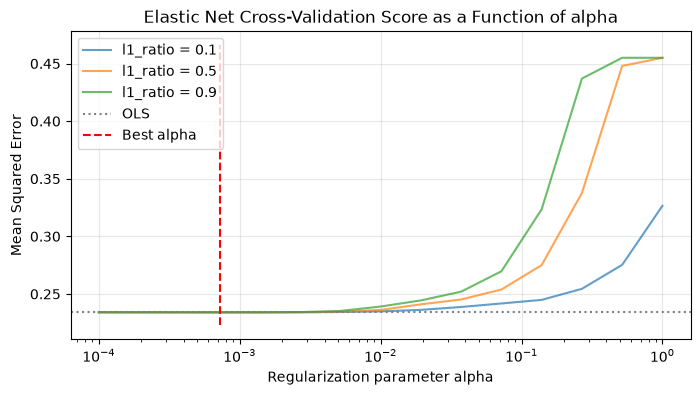

In [22]:
# Plot: Elastic Net CV error for each alpha, one line per l1_ratio
fig, ax = plt.subplots(figsize=(8, 4))

# CV error for each alpha, one line for each mix of the penalties
for l1 in l1_ratios:
    ax.plot(alphas_enet, enet_table[l1], alpha=0.7, label=f"l1_ratio = {l1}")
# OLS for comparison
ax.axhline(ols_cv_mse, color="grey", linestyle=":", label="OLS")
# The chosen alpha
ax.vlines(best_alpha_enet, ax.get_ylim()[0], ax.get_ylim()[1], linestyle="--", color="red", label="Best alpha")

# Aesthetics
ax.set_xscale("log")        # alphas are spread on a log scale
ax.set_xlabel("Regularization parameter alpha")
ax.set_ylabel("Mean Squared Error")
ax.set_title("Elastic Net Cross-Validation Score as a Function of alpha")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

In [23]:
# Fit Elastic Net with the best alpha and l1_ratio on all training households
enet = Pipeline([
    ("prep", make_preprocessor(features)),
    ("model", ElasticNet(alpha=best_alpha_enet, l1_ratio=best_l1_enet, max_iter=10000)),
])
enet.fit(X_train, y_train)                                      
enet_coefs = pd.Series(enet.named_steps["model"].coef_,
                       index=enet.named_steps["prep"].get_feature_names_out())   
zero_enet = enet_coefs[enet_coefs == 0].index.tolist()       # features with coefficient exactly 0

print(f"coefficients set to 0: {len(zero_enet)} of {len(features)}")
print(zero_enet)     # names of the dropped features

compare_enet = pd.DataFrame({"OLS": ols_coefs, "Lasso": lasso_coefs, "Elastic Net": enet_coefs})   
display(compare_enet.loc[top].round(3))                         # same 10 features as in the OLS table

coefficients set to 0: 3 of 53
['eschild', 'hhage', 'hhsector1']


,OLS,Lasso,Elastic Net
hhsize,-0.571,-0.537,-0.538
hhsize2,0.346,0.318,0.319
pcfloor,0.079,0.081,0.081
se2_117,0.072,0.072,0.072
fcook,0.069,0.069,0.069
se2_125,0.067,0.067,0.067
se2_126_127,0.067,0.066,0.066
se2_119,0.061,0.062,0.061
hhage2,-0.058,-0.019,-0.019
se2_18,0.053,0.052,0.052


In [24]:
# Recall at the quota for Elastic Net: same folds and same quota as in section 7
enet_rows = []                                                     # one row per fold
for k, (train_idx, val_idx) in enumerate(cv.split()):              # same 5 village folds
    val = train.iloc[val_idx].copy()                               # the validation villages
    enet_fold = Pipeline([
        ("prep", make_preprocessor(features)),
        ("model", ElasticNet(alpha=best_alpha_enet, l1_ratio=best_l1_enet, max_iter=10000)),
    ])
    enet_fold.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])     # learn on the other 4 folds
    val["Elastic Net"] = enet_fold.predict(X_train.iloc[val_idx])       # predicted log consumption in fold k
    enet_rows.append(targeting_metrics(val, "Elastic Net", "Elastic Net", k))

fold_results_all = pd.concat([fold_results, pd.DataFrame(enet_rows)], ignore_index=True)   # section 7 + Elastic Net

# Mean and standard deviation across the 5 folds
summary_all = fold_results_all.groupby("model")[["recall", "precision", "accuracy", "roc_auc"]].agg(["mean", "std"])
summary_all = summary_all.sort_values(("recall", "mean"), ascending=False)
display(summary_all.round(3))

candidates = summary_all.drop(index="Government formula")
best_mean = candidates[("recall", "mean")].iloc[0]                 
best_std = candidates[("recall", "std")].iloc[0]                   
within = candidates.index[candidates[("recall", "mean")] >= best_mean - best_std].tolist()
print(f"best mean recall: {best_mean:.3f} (std {best_std:.3f})")

recall        precision        accuracy        roc_auc  \
                     mean    std      mean    std     mean    std    mean   
model                                                                       
Lasso               0.562  0.030     0.631  0.045    0.722  0.017   0.822   
Elastic Net         0.562  0.029     0.630  0.044    0.721  0.016   0.822   
OLS                 0.561  0.030     0.629  0.043    0.721  0.016   0.822   
Ridge               0.561  0.031     0.629  0.045    0.721  0.017   0.823   
Government formula  0.540  0.024     0.606  0.038    0.706  0.013   0.795   

                           
                      std  
model                      
Lasso               0.022  
Elastic Net         0.022  
OLS                 0.021  
Ridge               0.021  
Government formula  0.026

best mean recall: 0.562 (std 0.030)


**Result**

The best Elastic Net is almost pure Lasso (l1_ratio 0.9, alpha 0.0007). It has the same error (MSE 0.234), drops the same 3 features, and has almost the same coefficients as Lasso.
On the plot, the more Lasso is in the mix, the earlier the error goes up, because more coefficients become 0.
Recall at the quota is 56.2%, the same as OLS, Ridge and Lasso. So mixing the penalties does not help either. With the simplicity rule, we still prefer OLS.


### 9. Boosting regressor

Boosting uses set A with the village-level columns (district, urban, village facilities), because trees can combine them with household features. It needs no scaling, because a tree only asks if a value is above or below a cutoff.

Boosting has many settings, so we do not try every combination. RandomizedSearchCV tries 40 random combinations from the grid in our outline, on the same village folds, and keeps the one with the lowest CV MSE. We turn off the built-in early stopping, because it would hold out random households and ignore the villages.

In [25]:
# Boosting, set A
features_boost = SET_A                                    # 62 formula variables + 3 indicators + district
X_train_boost = train[features_boost].copy()              # same training households, more columns
num_cols = [c for c in features_boost if c != "kabu"]     # all columns except the district code
X_train_boost[num_cols] = X_train_boost[num_cols].astype(float)   # decimal numbers (<NA> becomes NaN)

boost = Pipeline([
    ("prep", make_preprocessor(features_boost, scale=False)),    # fill missing values + district one-hot, no scaling
    ("model", HistGradientBoostingRegressor(early_stopping=False, random_state=SEED)),   # no built-in early stopping
])


param_distributions = {
    "model__learning_rate": [0.02, 0.05, 0.1],        # how much each new tree corrects
    "model__max_iter": [100, 200, 400, 800],          # number of trees
    "model__max_depth": [2, 3, 4, 5],                 # how deep each tree can grow
    "model__min_samples_leaf": [20, 50, 100],         # minimum households in a leaf (bigger = smoother)
    "model__l2_regularization": [0, 0.1, 1],          # penalty on the leaf values
}

search = RandomizedSearchCV(                          
    boost, param_distributions=param_distributions,
    n_iter=40,                                         # 40 random combinations
    scoring="neg_mean_squared_error",                  
    cv=cv,                                             # 5 village folds
    random_state=SEED,                               
    return_train_score=True,                           # keep the training error (to see overfitting)
    n_jobs=-1,                                         # use all processor cores (faster)
)
search.fit(X_train_boost, y_train)                     # tries all 40, then refits the best on all training households

best_params_boost = search.best_params_                # the best settings
best_score_boost = -search.best_score_                 # their CV MSE (flip the sign)
print("Best settings:", best_params_boost)
print(f"Boosting CV MSE: {best_score_boost:.5f} | OLS CV MSE: {ols_cv_mse:.5f}")

Best settings: {'model__min_samples_leaf': 50, 'model__max_iter': 200, 'model__max_depth': 2, 'model__learning_rate': 0.1, 'model__l2_regularization': 1}
Boosting CV MSE: 0.22191 | OLS CV MSE: 0.23415


In [26]:
# The 5 best combinations
results_boost = pd.DataFrame(search.cv_results_)                  # one row per combination that was tried
results_boost["CV MSE"] = -results_boost["mean_test_score"]       # flip the sign
results_boost["CV MSE std"] = results_boost["std_test_score"]     # spread across the 5 folds
results_boost["train MSE"] = -results_boost["mean_train_score"]   # error on the data the model learned from

show = ["param_model__learning_rate", "param_model__max_iter", "param_model__max_depth",
        "param_model__min_samples_leaf", "param_model__l2_regularization",
        "CV MSE", "CV MSE std", "train MSE"]
display(results_boost.sort_values("CV MSE")[show].head(5).round(4))

,param_model__learning_rate,param_model__max_iter,param_model__max_depth,param_model__min_samples_leaf,param_model__l2_regularization,CV MSE,CV MSE std,train MSE
8,0.10,200,2,50,1.0,0.2219,0.0132,0.1948
7,0.02,800,3,50,0.1,0.2229,0.0130,0.1788
19,0.05,800,2,100,0.1,0.2231,0.0137,0.1880
29,0.10,400,2,20,0.0,0.2233,0.0140,0.1773
2,0.02,800,2,20,0.0,0.2235,0.0153,0.1965


In [27]:
# Recall at the quota for boosting
boost_rows = []                                                    # one row per fold
for k, (train_idx, val_idx) in enumerate(cv.split()):              # same 5 village folds
    val = train.iloc[val_idx].copy()                               # the validation villages
    boost_fold = Pipeline([
        ("prep", make_preprocessor(features_boost, scale=False)),
        ("model", HistGradientBoostingRegressor(early_stopping=False, random_state=SEED)),
    ])
    boost_fold.set_params(**best_params_boost)                     # use the best settings from the search
    boost_fold.fit(X_train_boost.iloc[train_idx], y_train.iloc[train_idx])     # learn on the other 4 folds
    val["Boosting"] = boost_fold.predict(X_train_boost.iloc[val_idx])          # predicted log consumption in fold k
    boost_rows.append(targeting_metrics(val, "Boosting", "Boosting", k))

fold_results_boost = pd.concat([fold_results_all, pd.DataFrame(boost_rows)], ignore_index=True)   # all models so far

# Recall in every fold
display(fold_results_boost.pivot(index="fold", columns="model", values="recall").round(3))

# Mean and sd
summary_boost = fold_results_boost.groupby("model")[["recall", "precision", "accuracy", "roc_auc"]].agg(["mean", "std"])
summary_boost = summary_boost.sort_values(("recall", "mean"), ascending=False)
display(summary_boost.round(3))

candidates = summary_boost.drop(index="Government formula")       # the government formula is a baseline, not a candidate
best_mean = candidates[("recall", "mean")].iloc[0]
best_std = candidates[("recall", "std")].iloc[0]
within = candidates.index[candidates[("recall", "mean")] >= best_mean - best_std].tolist()
print(f"best mean recall: {best_mean:.3f} (std {best_std:.3f})")
print("candidates within one std of the best:", within)

model,Boosting,Elastic Net,Government formula,Lasso,OLS,Ridge
fold,,,,,,
0,0.582,0.589,0.559,0.592,0.589,0.592
1,0.582,0.582,0.544,0.582,0.582,0.582
2,0.548,0.551,0.548,0.551,0.545,0.545
3,0.583,0.569,0.552,0.569,0.573,0.569
4,0.509,0.516,0.498,0.516,0.516,0.516


recall        precision        accuracy        roc_auc  \
                     mean    std      mean    std     mean    std    mean   
model                                                                       
Lasso               0.562  0.030     0.631  0.045    0.722  0.017   0.822   
Elastic Net         0.562  0.029     0.630  0.044    0.721  0.016   0.822   
OLS                 0.561  0.030     0.629  0.043    0.721  0.016   0.822   
Ridge               0.561  0.031     0.629  0.045    0.721  0.017   0.823   
Boosting            0.561  0.033     0.629  0.041    0.721  0.012   0.835   
Government formula  0.540  0.024     0.606  0.038    0.706  0.013   0.795   

                           
                      std  
model                      
Lasso               0.022  
Elastic Net         0.022  
OLS                 0.021  
Ridge               0.021  
Boosting            0.017  
Government formula  0.026

best mean recall: 0.562 (std 0.030)
candidates within one std of the best: ['Lasso', 'Elastic Net', 'OLS', 'Ridge', 'Boosting']


**Result:**

The best boosting model is simple: small trees (depth 2), 200 trees and a strong penalty. Its CV error is  lower than for OLS (MSE 0.222 vs. 0.234), and it does not overfit much (training MSE 0.195).

But recall at the quota is the same as for the linear models: 56.1%. Fold by fold, boosting is better in 2 folds, worse in 2 and equal in 1. So it does not find more poor households. The reason is the village-level columns. They help boosting to predict which villages are richer, which lowers the MSE. But the quota ranks households within each village, and inside a village these columns are the same for everyone. So they cannot help with the ranking.

### 10. Regression winner

Here we put all models of the regression race together and choose the winner with the rule from our outline. We rank the models by their mean CV recall at the quota. If a simpler model is within one standard deviation of the best one, the simpler model wins, because a government has to publish and explain its formula. Linear models count as simpler than boosting, and OLS is the simplest, because it has nothing to tune. The government formula is only a reference, not a candidate.

In [28]:
# All models of the regression race in one table
cv_mse = pd.Series({"OLS": ols_cv_mse, "Ridge": best_score_ridge, "Lasso": best_score_lasso,
                    "Elastic Net": best_score_enet, "Boosting": best_score_boost})   # CV MSE (the tuning score)

final = pd.DataFrame({
    "CV MSE": cv_mse,                                       # empty for the government formula (no fitting)
    "recall mean": summary_boost[("recall", "mean")],       # main metric
    "recall std": summary_boost[("recall", "std")],         # spread across the 5 folds
    "ROC AUC": summary_boost[("roc_auc", "mean")],          # ranking quality without the quota
}).sort_values("recall mean", ascending=False)
display(final.round(3))

simplicity_order = ["OLS", "Ridge", "Lasso", "Elastic Net", "Boosting"]   # simplest first
candidates = final.drop(index="Government formula")                      # baseline, not a candidate
best = candidates["recall mean"].idxmax()                                # model with the best mean recall
threshold = candidates.loc[best, "recall mean"] - candidates.loc[best, "recall std"]
within = candidates.index[candidates["recall mean"] >= threshold].tolist()
winner = [m for m in simplicity_order if m in within][0]                 # the simplest of these

print(f"best mean recall: {best} ({candidates.loc[best, 'recall mean']:.3f}, std {candidates.loc[best, 'recall std']:.3f})")
print("within one std of the best:", within)
print("regression winner:", winner)

,CV MSE,recall mean,recall std,ROC AUC
Lasso,0.234,0.562,0.030,0.822
Elastic Net,0.234,0.562,0.029,0.822
OLS,0.234,0.561,0.030,0.822
Ridge,0.234,0.561,0.031,0.823
Boosting,0.222,0.561,0.033,0.835
Government formula,NaN,0.540,0.024,0.795


best mean recall: Lasso (0.562, std 0.030)
within one std of the best: ['Lasso', 'Elastic Net', 'OLS', 'Ridge', 'Boosting']
regression winner: OLS


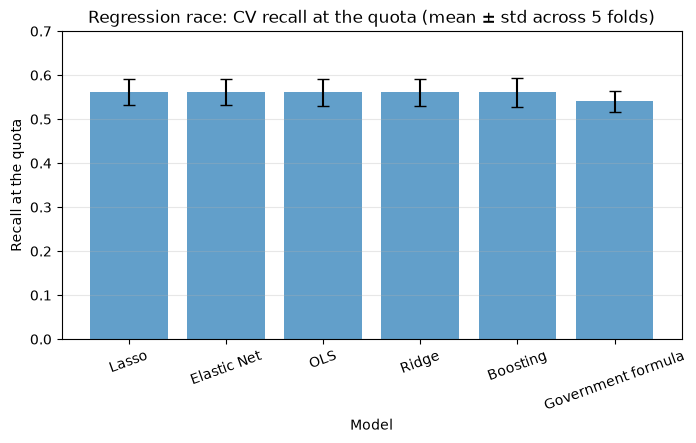

In [30]:
# Plot
fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(final.index, final["recall mean"], yerr=final["recall std"],  
       capsize=4, alpha=0.7)

# Aesthetics
ax.set_ylim(0, 0.7)                        
ax.set_xlabel("Model")
ax.set_ylabel("Recall at the quota")
ax.set_title("Regression race: CV recall at the quota (mean ± std across 5 folds)")
ax.grid(axis="y", alpha=0.3)
ax.tick_params(axis="x", rotation=20)      # no overlap of the model name
plt.show()

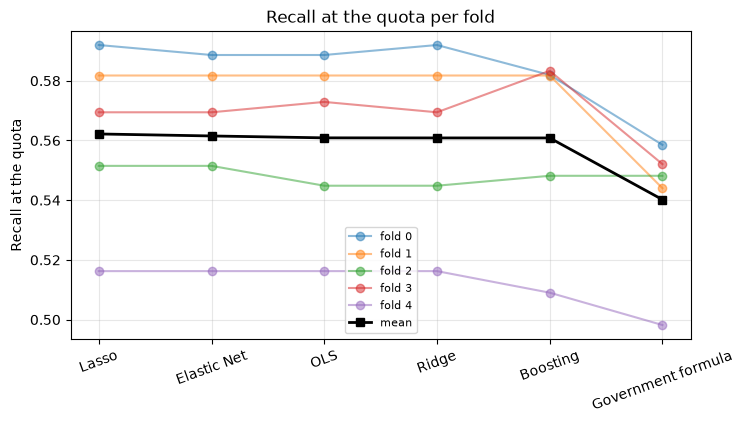

In [ ]:
# Plot 2
recall_by_fold = fold_results_boost.pivot(index="fold", columns="model", values="recall")[final.index]  

fig, ax = plt.subplots(figsize=(8, 4))
for k in recall_by_fold.index:                                       # one line per fold
    ax.plot(recall_by_fold.columns, recall_by_fold.loc[k], marker="o", alpha=0.5, label=f"fold {k}")
ax.plot(final.index, final["recall mean"], color="black", marker="s", linewidth=2, label="mean") 

# Aesthetics
ax.set_ylabel("Recall at the quota")
ax.set_title("Recall at the quota per fold")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
ax.tick_params(axis="x", rotation=20)
plt.show()


**Conclusion**

In this notebook we predicted log consumption with five models: OLS, Ridge, Lasso, Elastic Net and boosting. We used the same village folds for all models. All filling and scaling happened inside the pipeline, so it was learned only from the training folds. The test villages were not used.

With the MSE, the four linear models are tied (about 0.234). The penalty does not help, because we have many households per feature, and the features from the government formula were already chosen to be useful. Boosting has a lower MSE (0.222), because it also uses the village-level columns and can predict which villages are richer.

But the government does not need exact numbers. It needs to choose the right households in each village. With recall at the quota, all five models find about 56 out of 100 poor households. Boosting does not find more, because the village-level columns are the same for everyone in a village, so they do not help with the ranking within a village.

All models find about 2 more poor households out of 100 than the government formula (54%), in 4 of the 5 folds. But this gain is smaller than the differences between the folds, so we cannot be sure yet that it holds in new villages.

With the simplicity rule, OLS is the winner of the regression race. It is as good as the other models, it has nothing to tune, and it is the easiest for a government to explain. 
